<a href="https://colab.research.google.com/github/mohamednasfan/SE4050-DeepLearning-Lab1/blob/main/lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. 4x4 Exponential Array:
 [[0.93969554 0.94742218 0.46762423 3.16972035]
 [0.45735108 0.14473056 0.50989867 0.59937203]
 [2.48115996 0.12078719 1.67080222 0.03970448]
 [1.28532162 3.68741642 0.61363812 0.02827841]] 



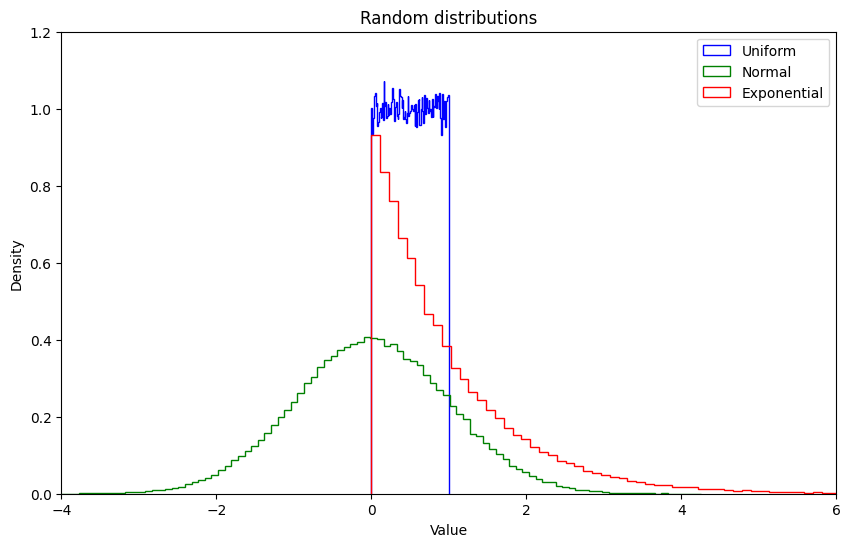

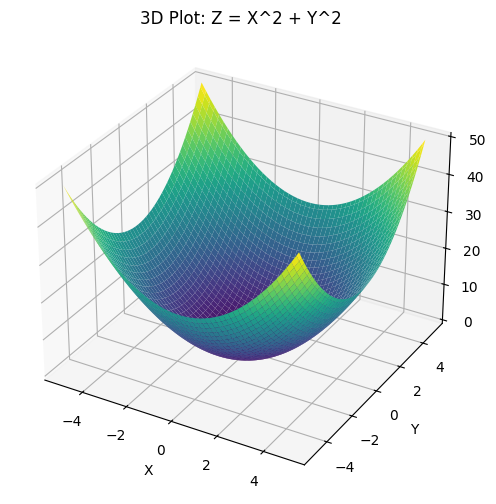

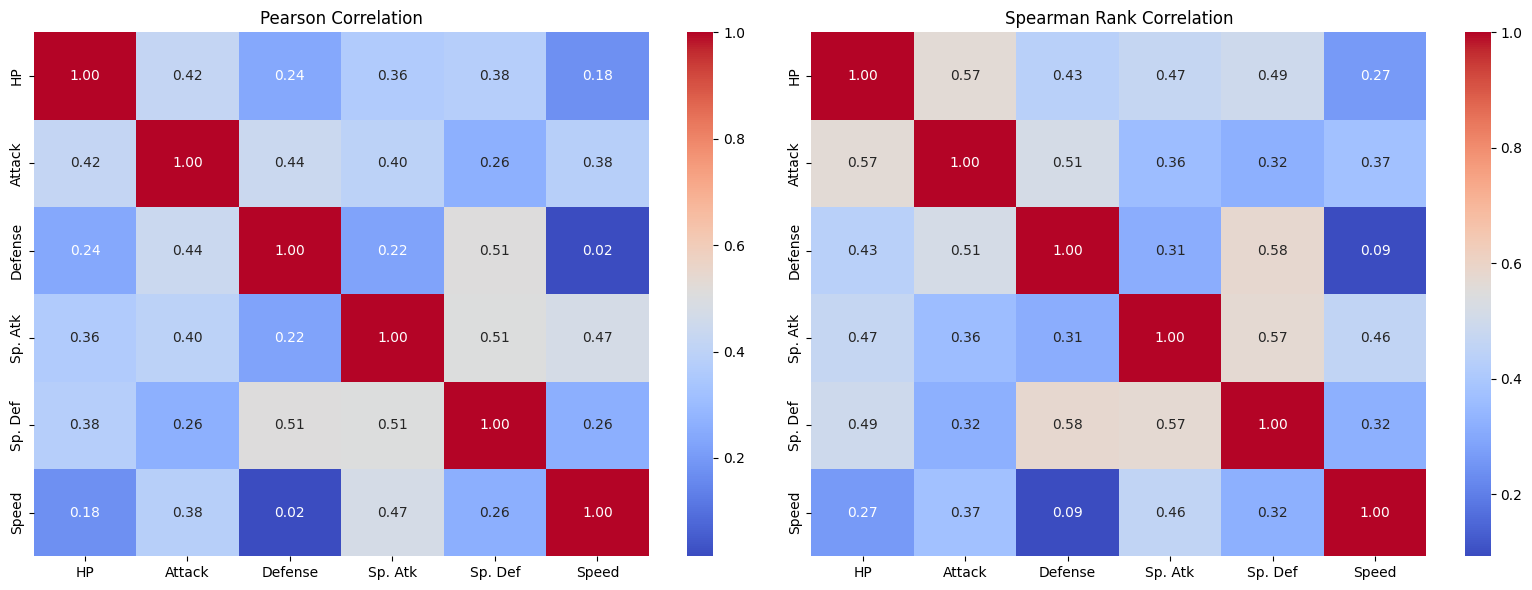

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Create a random 4x4 array from an exponential distribution
exp_array_4x4 = np.random.exponential(scale=1.0, size=(4, 4))
print("1. 4x4 Exponential Array:\n", exp_array_4x4, "\n")

# 2. Visualize exponential, uniform, and normal distributions
exp_data = np.random.exponential(scale=1.0, size=100000)
uniform_data = np.random.rand(100000)
normal_data = np.random.randn(100000)

plt.figure(figsize=(10, 6))
plt.hist(uniform_data, density=True, bins=100, histtype="step", color="blue", label="Uniform")
plt.hist(normal_data, density=True, bins=100, histtype="step", color="green", label="Normal")
plt.hist(exp_data, density=True, bins=100, histtype="step", color="red", label="Exponential")
plt.axis([-4, 6, 0, 1.2]) # Adjusted axes to show everything clearly
plt.legend(loc="upper right")
plt.title("Random distributions")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

# 3. 3D plot of Z = X**2 + Y**2
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_title("3D Plot: Z = X^2 + Y^2")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

# 4. Pearson and Spearman correlations with heatmaps (using the Pokemon dataset typical for seaborn tutorial)
url = "https://gist.githubusercontent.com/armgilles/194bcff35001e7eb53a2a8b441e8b2c6/raw/92200bc0a673d5ce2110aaad4544ed6c4010f687/pokemon.csv"
df = pd.read_csv(url)

# Note: The lab sheet mentions "Sp. Ark" which is a typo for "Sp. Atk"
features = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']
subset_df = df[features]

pearson_corr = subset_df.corr(method='pearson')
spearman_corr = subset_df.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson Heatmap
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', ax=axes[0], fmt=".2f")
axes[0].set_title('Pearson Correlation')

# Spearman Heatmap
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', ax=axes[1], fmt=".2f")
axes[1].set_title('Spearman Rank Correlation')

plt.tight_layout()
plt.show()


In [16]:
from google.colab import files
uploaded = files.upload()


Saving Au_nanoparticle_dataset.csv to Au_nanoparticle_dataset (4).csv


First 20 samples:


,N_total,N_bulk,N_surface,R_avg
0,1599,1014,585,17.3706
1,1642,1034,608,17.6061
2,4637,3365,1272,25.3692
3,7189,5292,1897,29.7011
4,11004,8508,2496,34.2831
5,13375,10768,2607,36.6334
6,13795,11155,2640,37.0108
7,13947,11304,2643,37.1672
8,14020,11357,2663,37.2103
9,14056,11389,2667,37.2467



Statistics (Mean, Std, Quartiles):


,N_total,N_bulk,N_surface,R_avg
mean,3476.786500,2521.550250,955.23625,20.654363
std,3679.286769,2976.232459,721.87022,7.610716
25%,1061.000000,618.750000,437.00000,15.160725
50%,1867.000000,1199.000000,666.00000,18.629250
75%,4503.000000,3183.000000,1301.75000,25.525125


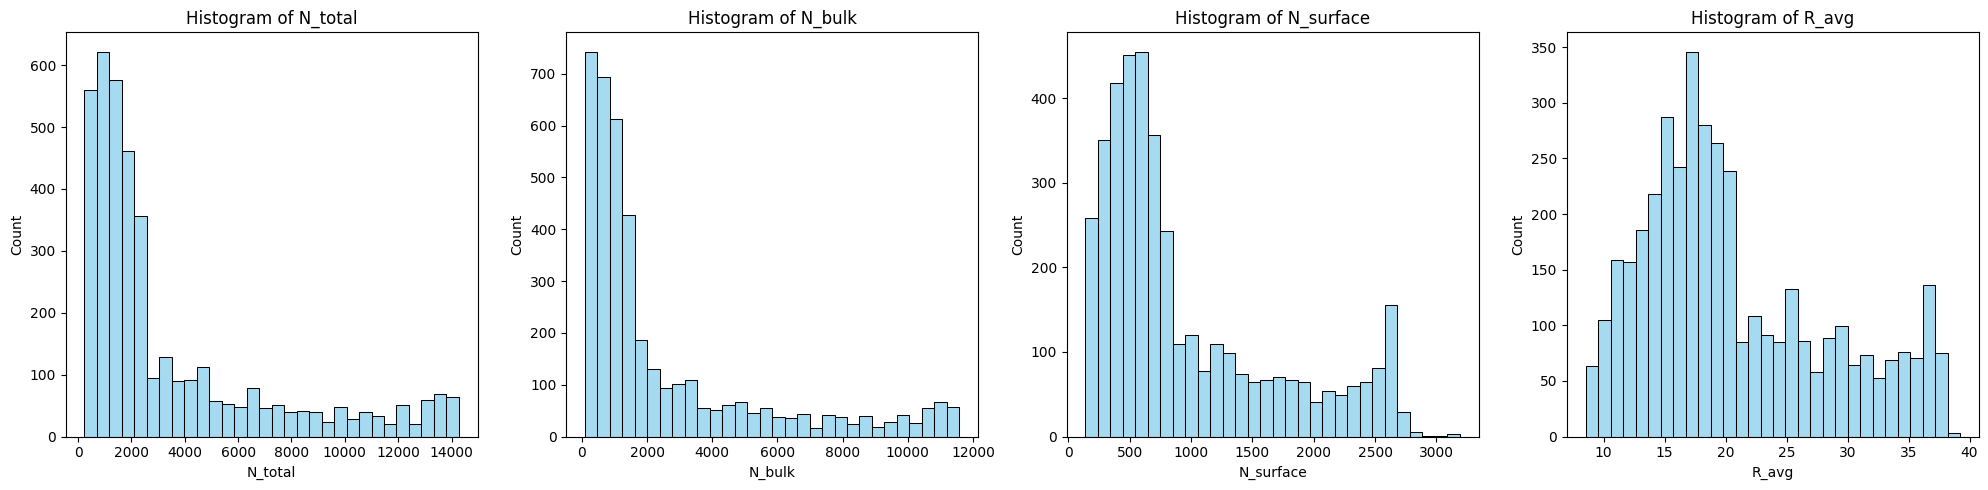


Pairplot:


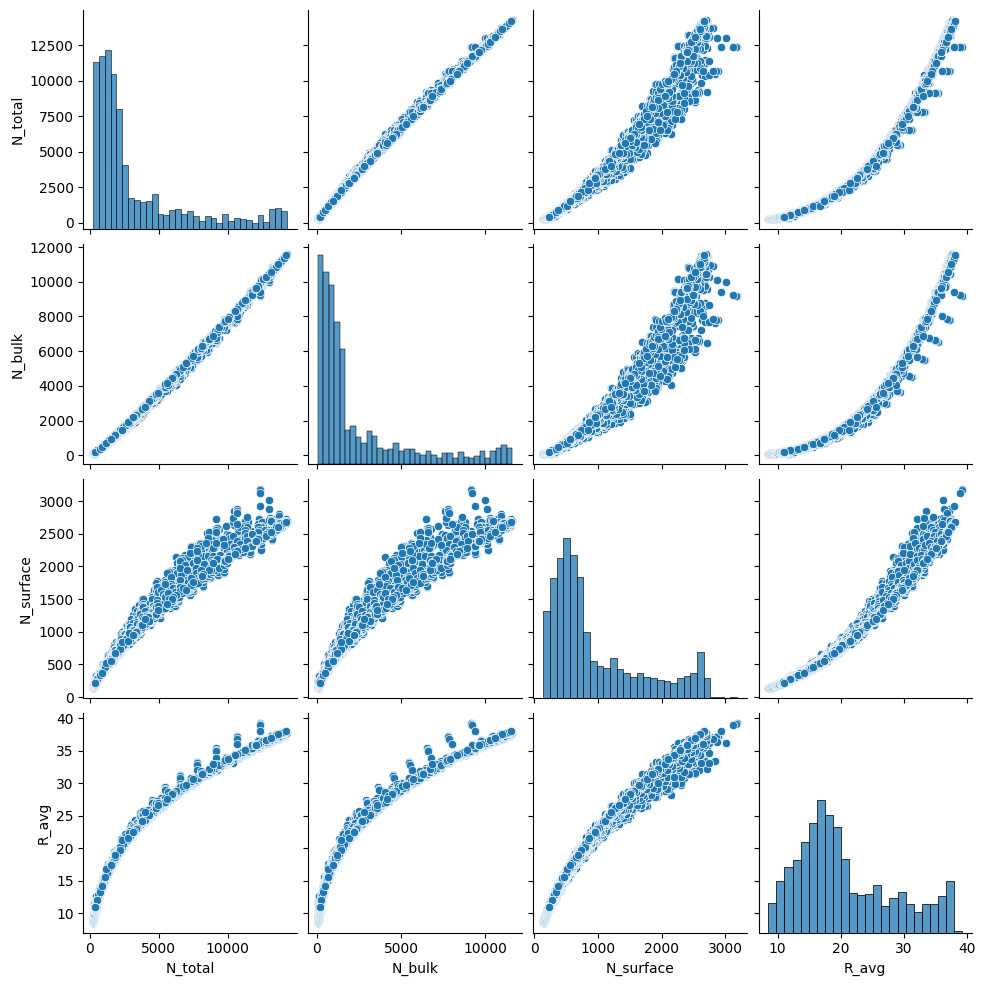


Custom PairGrid:


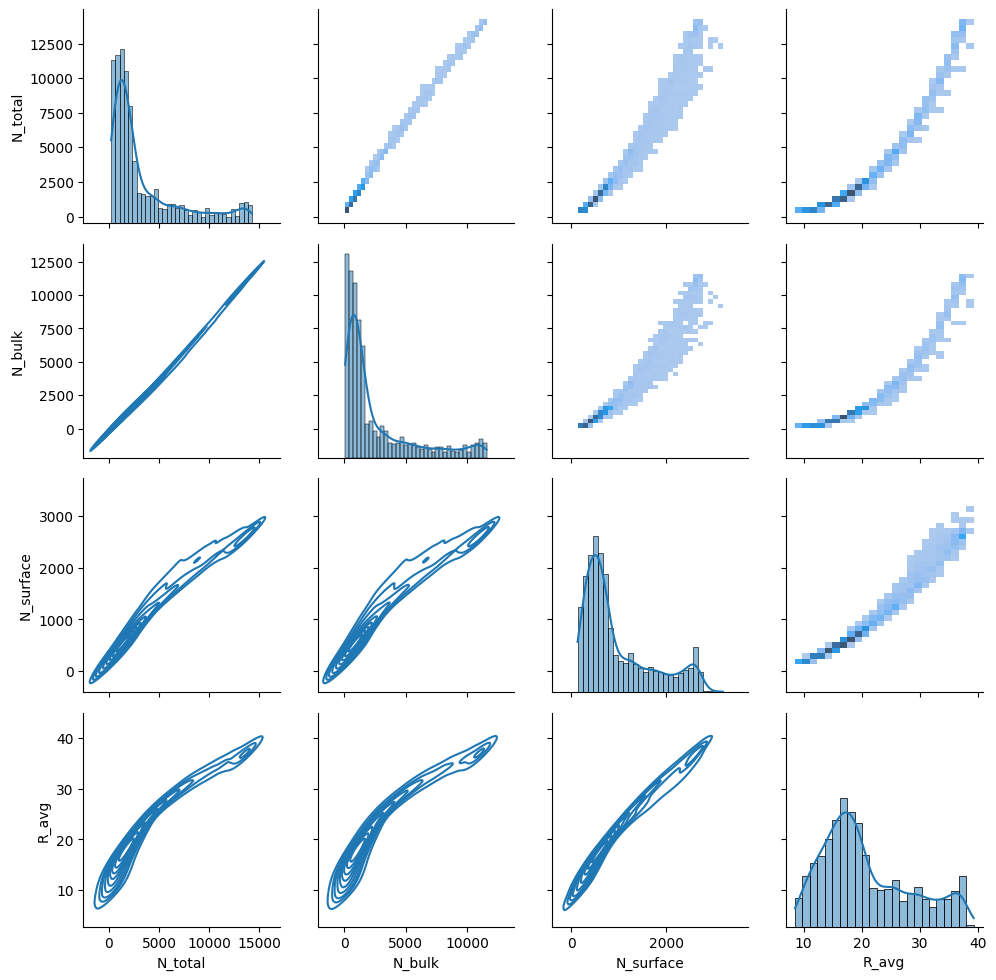

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset (Assuming the file is uploaded to the Colab environment)
df = pd.read_csv('Au_nanoparticle_dataset (4).csv')

# 1. Create a new dataframe by filtering all columns except N_total, N_bulk, N_surface, and R_avg
new_df = df[['N_total', 'N_bulk', 'N_surface', 'R_avg']]

# 2. Display the first 20 samples of this dataframe
print("First 20 samples:")
display(new_df.head(20)) # If using Colab/Jupyter, 'display()' looks better than 'print()'

# 3. Calculate mean, standard deviation, and quartile values
stats_df = new_df.describe().loc[['mean', 'std', '25%', '50%', '75%']]
print("\nStatistics (Mean, Std, Quartiles):")
display(stats_df)

# 4. Plot the histogram of each of these features in a 1x4 layout
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, col in enumerate(new_df.columns):
    sns.histplot(new_df[col], bins=30, ax=axes[i], color='skyblue', kde=False)
    axes[i].set_title(f'Histogram of {col}')
plt.tight_layout()
plt.show()

# 5. Visualize scatter plots and histograms using seaborn pairplot
print("\nPairplot:")
sns.pairplot(new_df)
plt.show()

# 6. Custom PairGrid with specific plots
print("\nCustom PairGrid:")
g = sns.PairGrid(new_df)
g.map_upper(sns.histplot)                 # a. Bivariate histogram on upper half
g.map_diag(sns.histplot, kde=True)        # a. Histogram with KDE on the diagonal
g.map_lower(sns.kdeplot)                  # b. Bivariate KDE plot on lower half
plt.show()
